In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv
/kaggle/input/datasets/dgawlik/nyse/fundamentals.csv
/kaggle/input/datasets/dgawlik/nyse/prices.csv
/kaggle/input/datasets/dgawlik/nyse/securities.csv


In [2]:
import pandas as pd
data = pd.read_csv("/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv")
data.head()

,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [3]:
data.shape[0]

851264

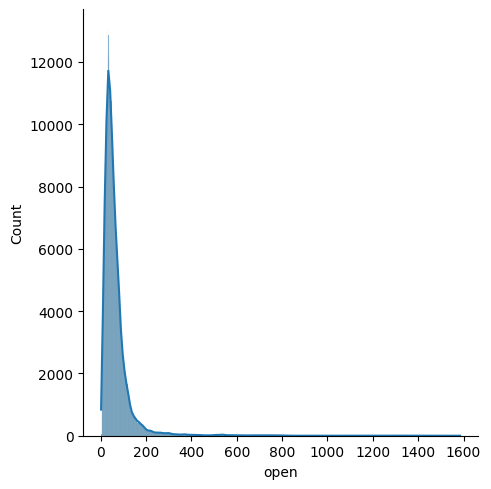

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
data_sales = pd.DataFrame(data['open'])
sns.displot(data_sales, x="open",kde=True)
plt.show()

In [5]:
print(data.head())
print(data.shape)
print(data.columns.tolist())
print(data.dtypes)
print(data.isnull().sum())

         date symbol        open       close         low        high  \
0  2016-01-05   WLTW  123.430000  125.839996  122.309998  126.250000   
1  2016-01-06   WLTW  125.239998  119.980003  119.940002  125.540001   
2  2016-01-07   WLTW  116.379997  114.949997  114.930000  119.739998   
3  2016-01-08   WLTW  115.480003  116.620003  113.500000  117.440002   
4  2016-01-11   WLTW  117.010002  114.970001  114.089996  117.330002   

      volume  
0  2163600.0  
1  2386400.0  
2  2489500.0  
3  2006300.0  
4  1408600.0  
(851264, 7)
['date', 'symbol', 'open', 'close', 'low', 'high', 'volume']
date       object
symbol     object
open      float64
close     float64
low       float64
high      float64
volume    float64
dtype: object
date      0
symbol    0
open      0
close     0
low       0
high      0
volume    0
dtype: int64


In [6]:
data.describe()

,open,close,low,high,volume
count,851264.000000,851264.000000,851264.000000,851264.000000,8.512640e+05
mean,64.993618,65.011913,64.336541,65.639748,5.415113e+06
std,75.203893,75.201216,74.459518,75.906861,1.249468e+07
min,1.660000,1.590000,1.500000,1.810000,0.000000e+00
25%,31.270000,31.292776,30.940001,31.620001,1.221500e+06
50%,48.459999,48.480000,47.970001,48.959999,2.476250e+06
75%,75.120003,75.139999,74.400002,75.849998,5.222500e+06
max,1584.439941,1578.130005,1549.939941,1600.930054,8.596434e+08


In [7]:

data["date"] = pd.to_datetime(data["date"])

print("Number of stocks:", data["symbol"].nunique())
print("First date:", data["date"].min())
print("Last date:", data["date"].max())

print(data["symbol"].value_counts().head(10))

Number of stocks: 501
First date: 2010-01-04 00:00:00
Last date: 2016-12-30 00:00:00
symbol
VTR     1762
VZ      1762
WAT     1762
WBA     1762
WDC     1762
WEC     1762
WFC     1762
WFM     1762
VFC     1762
VIAB    1762
Name: count, dtype: int64


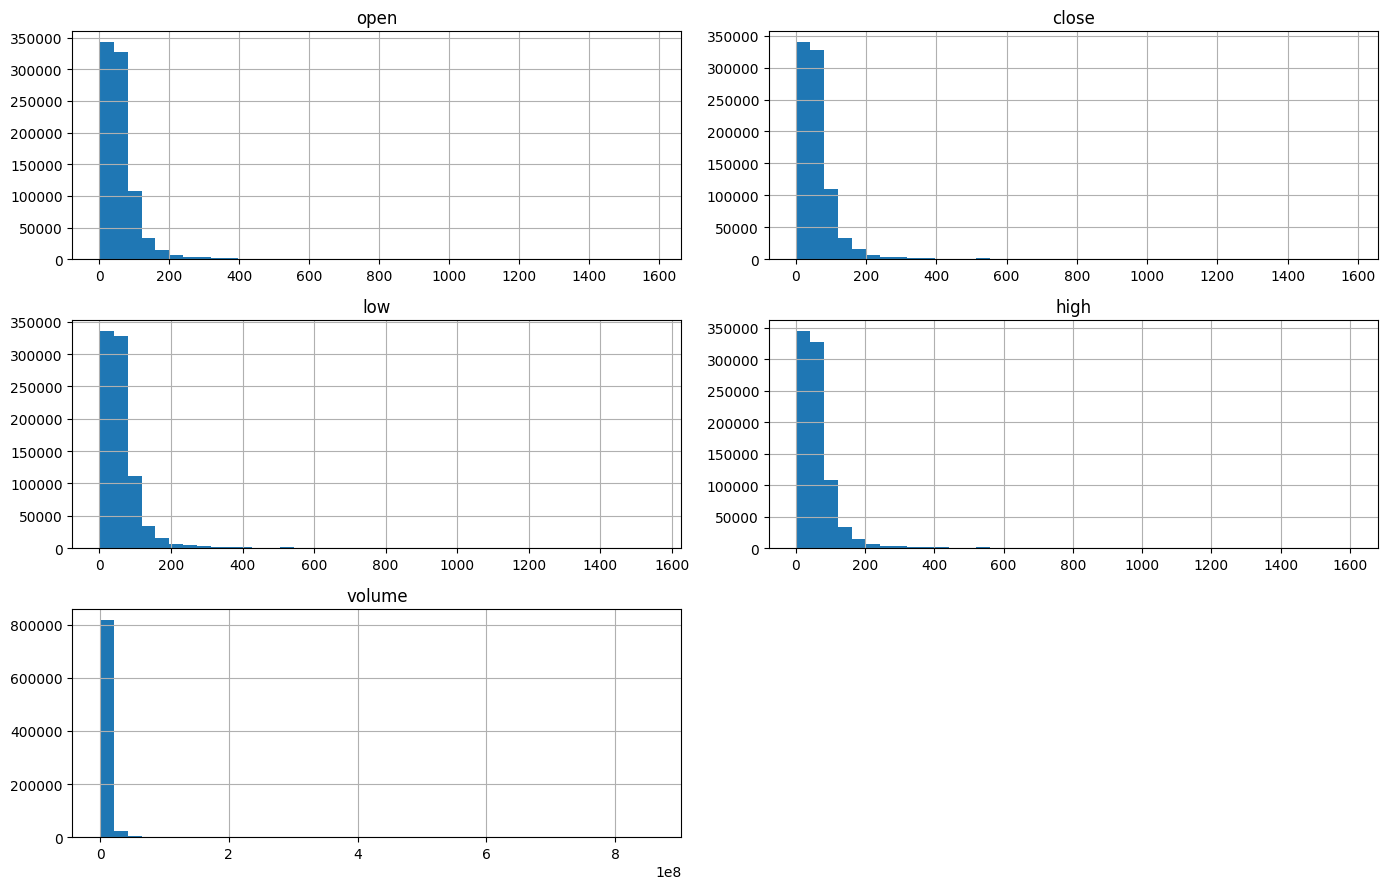

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = ["open", "close", "low", "high", "volume"]

data[numerical_cols].hist(
    figsize=(14, 9),
    bins=40
)

plt.tight_layout()
plt.show()

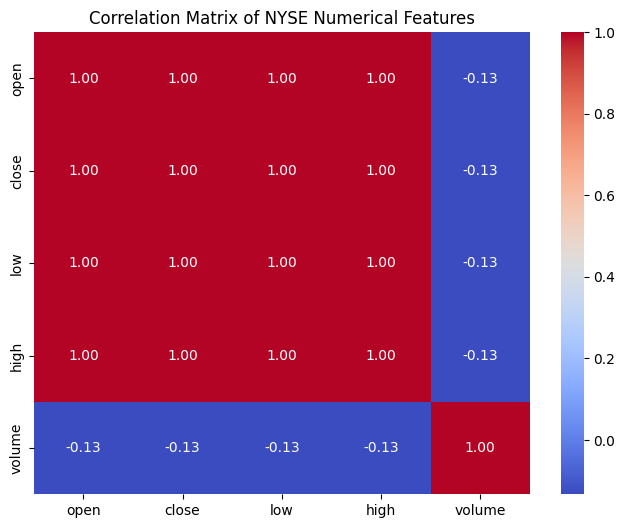

In [9]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    data[numerical_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of NYSE Numerical Features")
plt.show()

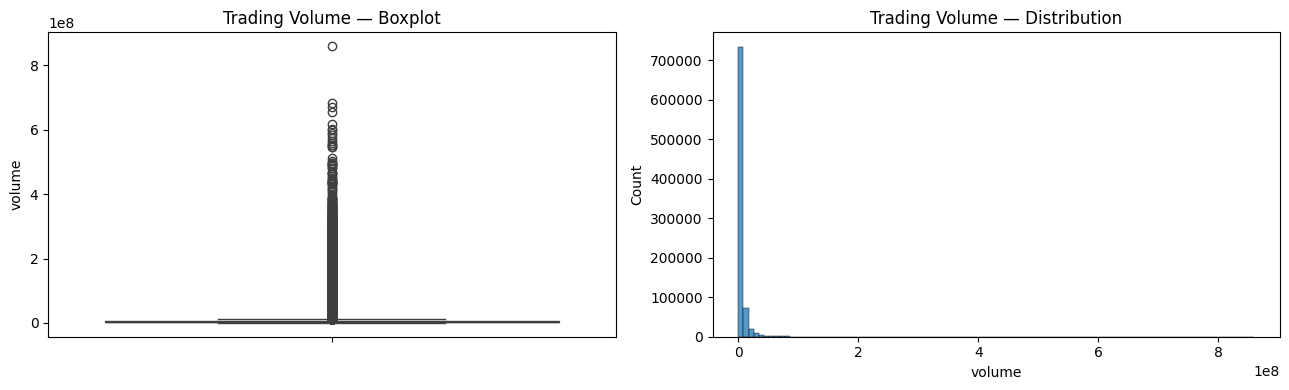

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.boxplot(y=data["volume"], ax=axes[0])
axes[0].set_title("Trading Volume — Boxplot")

sns.histplot(data=data, x="volume", bins=100, ax=axes[1])
axes[1].set_title("Trading Volume — Distribution")

plt.tight_layout()
plt.show()

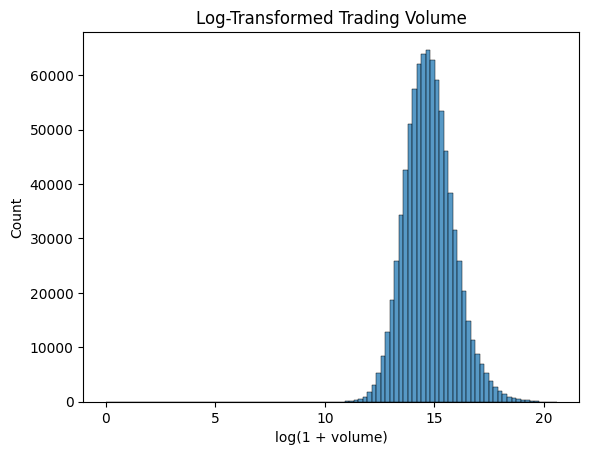

In [11]:
import numpy as np

sns.histplot(
    np.log1p(data["volume"]),
    bins=100
)

plt.title("Log-Transformed Trading Volume")
plt.xlabel("log(1 + volume)")
plt.show()


In [12]:
Q1 = data["volume"].quantile(0.25)
Q3 = data["volume"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[
    (data["volume"] < lower_bound) |
    (data["volume"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", len(outliers))
print("Percentage:", len(outliers) / len(data) * 100, "%")
print(outliers[["date", "symbol", "volume"]].head(10))


Lower bound: -4780000.0
Upper bound: 11224000.0
Potential outliers: 82488
Percentage: 9.690060897676867 %
          date symbol       volume
254 2010-01-04   AAPL  123432400.0
278 2010-01-04   AMAT   18615100.0
292 2010-01-04   ARNC   11512100.0
302 2010-01-04    BAC  180845200.0
303 2010-01-04    BAX   11467500.0
315 2010-01-04    BMY   14376100.0
316 2010-01-04    BSX   14332300.0
319 2010-01-04      C   40679300.0
333 2010-01-04    CHK   31146800.0
340 2010-01-04  CMCSA   13573400.0


In [13]:
zero_volume_count = (data["volume"] == 0).sum()

print("Records with zero volume:", zero_volume_count)
print("Percentage:", zero_volume_count / len(data) * 100, "%")

Records with zero volume: 21
Percentage: 0.002466919780467634 %


In [14]:
import pandas as pd

data["date"] = pd.to_datetime(data["date"])

# Sort each company's observations chronologically
data = data.sort_values(["symbol", "date"]).copy()

# Predict the next recorded closing price for each company
data["target_next_close"] = (
    data.groupby("symbol")["close"].shift(-1)
)

# Remove the last observation of each company,
# because its next closing price is unknown
data = data.dropna(subset=["target_next_close"]).copy()

print("Dataset shape:", data.shape)
print(data.head())
print(data.columns.tolist())

Dataset shape: (850763, 8)
           date symbol       open      close        low       high     volume  \
251  2010-01-04      A  22.453504  22.389128  22.267525  22.625180  3815500.0   
718  2010-01-05      A  22.324749  22.145923  22.002861  22.331903  4186000.0   
1186 2010-01-06      A  22.067240  22.067240  22.002861  22.174536  3243700.0   
1654 2010-01-07      A  22.017168  22.038626  21.816881  22.045780  3095100.0   
2122 2010-01-08      A  21.917024  22.031474  21.745350  22.067240  3733900.0   

      target_next_close  
251           22.145923  
718           22.067240  
1186          22.038626  
1654          22.031474  
2122          22.045780  
['date', 'symbol', 'open', 'close', 'low', 'high', 'volume', 'target_next_close']


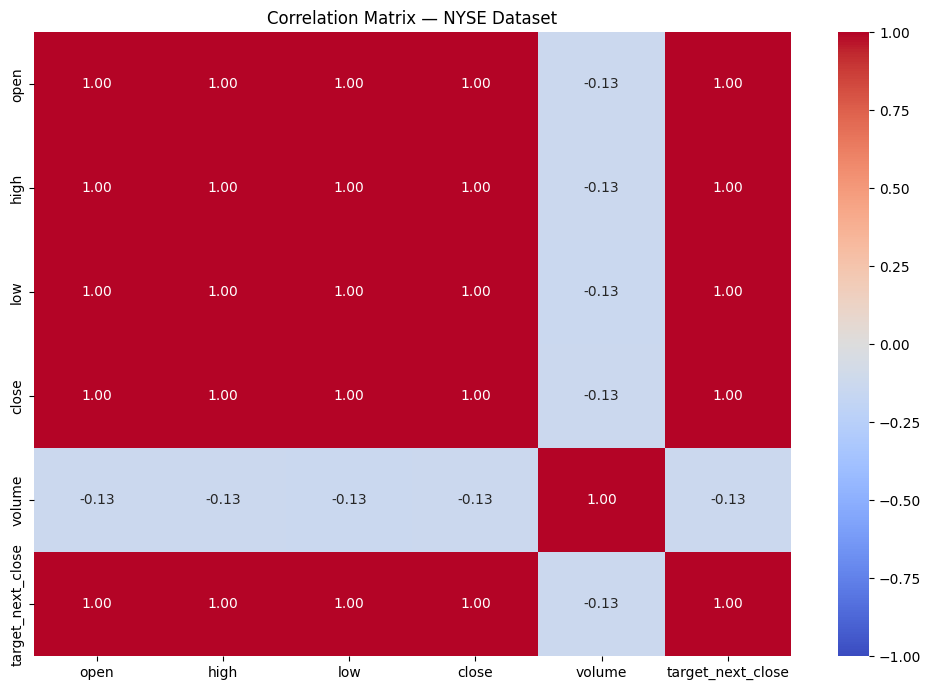

In [15]:
numerical_cols = [
    "open", "high", "low", "close",
    "volume", "target_next_close"
]

correlation_matrix = data[numerical_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Matrix — NYSE Dataset")
plt.tight_layout()
plt.show()

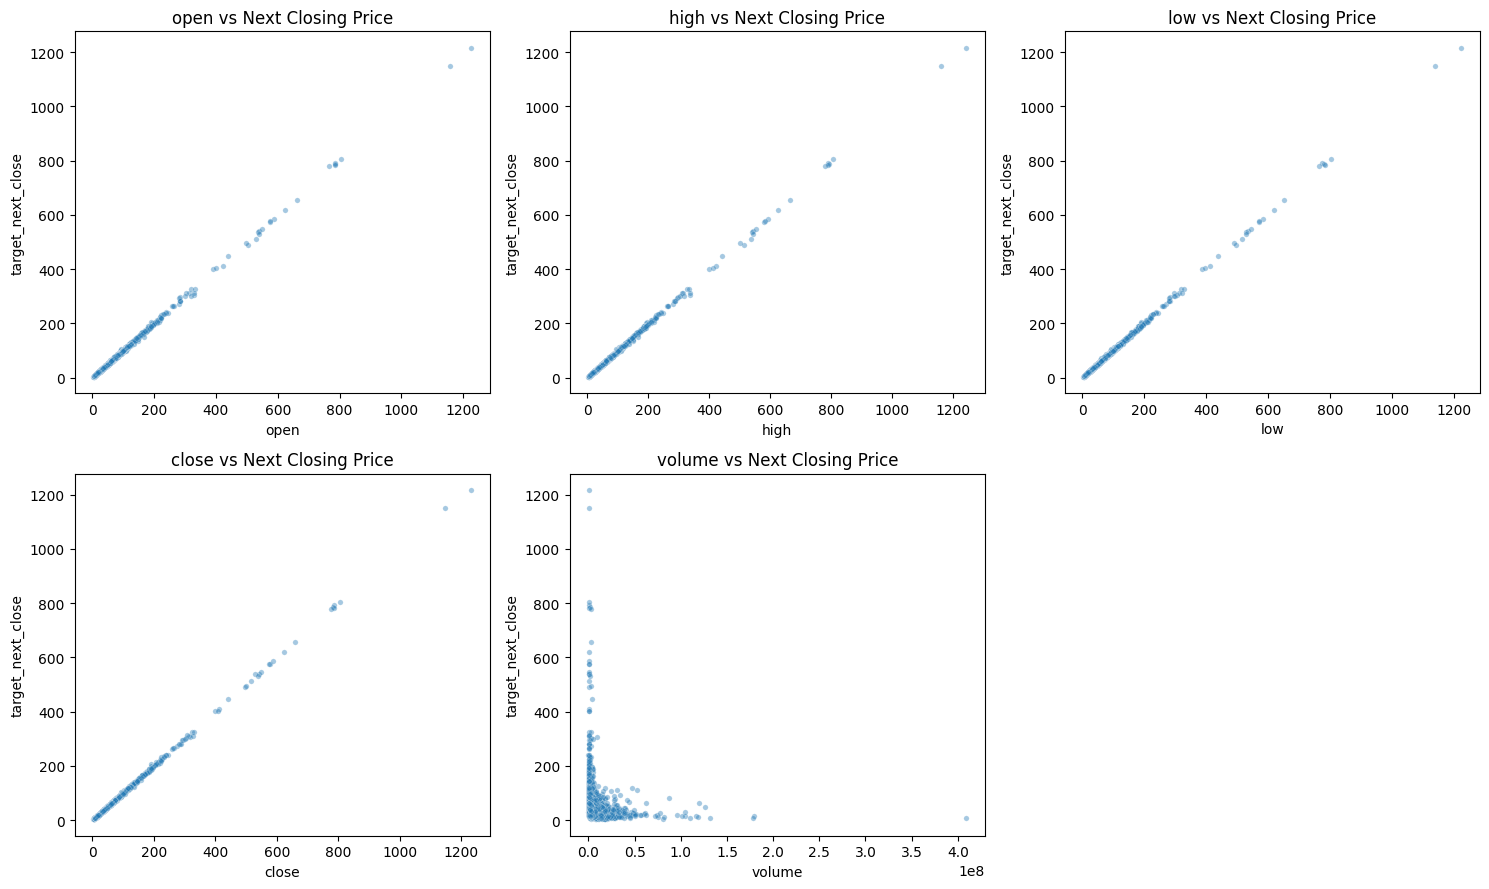

In [16]:
features = ["open", "high", "low", "close", "volume"]

# Use the same observations in every plot
plot_sample = data.sample(
    n=min(3000, len(data)),
    random_state=42
)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.scatterplot(
        data=plot_sample,
        x=feature,
        y="target_next_close",
        alpha=0.4,
        s=15,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Next Closing Price")

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [17]:
# Check that the target exists
print("Columns:", data.columns.tolist())
print("Dataset shape:", data.shape)

# Check missing values in the model columns
features = ["open", "high", "low", "close", "volume"]
target = "target_next_close"

print("\nMissing values:")
print(data[features + [target]].isnull().sum())

print("\nTarget statistics:")
print(data[target].describe())

print("\nNumber of stocks:", data["symbol"].nunique())
print("Date range:", data["date"].min(), "to", data["date"].max())

Columns: ['date', 'symbol', 'open', 'close', 'low', 'high', 'volume', 'target_next_close']
Dataset shape: (850763, 8)

Missing values:
open                 0
high                 0
low                  0
close                0
volume               0
target_next_close    0
dtype: int64

Target statistics:
count    850763.000000
mean         65.026981
std          75.216394
min           1.590000
25%          31.305000
50%          48.490002
75%          75.160004
max        1578.130005
Name: target_next_close, dtype: float64

Number of stocks: 501
Date range: 2010-01-04 00:00:00 to 2016-12-29 00:00:00


In [18]:
import numpy as np

# Sort unique dates so all stocks from the same date
# remain in the same chronological partition.
unique_dates = np.sort(data["date"].unique())

n_dates = len(unique_dates)
train_cutoff = int(n_dates * 0.70)
val_cutoff = int(n_dates * 0.85)

train_end_date = unique_dates[train_cutoff - 1]
val_end_date = unique_dates[val_cutoff - 1]

train_data = data[data["date"] <= train_end_date].copy()

val_data = data[
    (data["date"] > train_end_date) &
    (data["date"] <= val_end_date)
].copy()

test_data = data[data["date"] > val_end_date].copy()

print("Training:", train_data.shape)
print("Validation:", val_data.shape)
print("Testing:", test_data.shape)

print("\nTraining dates:",
      train_data["date"].min(), "to", train_data["date"].max())

print("Validation dates:",
      val_data["date"].min(), "to", val_data["date"].max())

print("Testing dates:",
      test_data["date"].min(), "to", test_data["date"].max())

Training: (587442, 8)
Validation: (130711, 8)
Testing: (132610, 8)

Training dates: 2010-01-04 00:00:00 to 2014-11-21 00:00:00
Validation dates: 2014-11-24 00:00:00 to 2015-12-10 00:00:00
Testing dates: 2015-12-11 00:00:00 to 2016-12-29 00:00:00


In [19]:
# Recover the date associated with each next-close target.
# This is used only to prevent targets from crossing split boundaries.
data["target_date"] = data.groupby("symbol")["date"].shift(-1)

# Rebuild the partitions using the same date boundaries.
train_data = data[
    (data["date"] <= train_end_date) &
    (data["target_date"] <= train_end_date)
].copy()

val_data = data[
    (data["date"] > train_end_date) &
    (data["date"] <= val_end_date) &
    (data["target_date"] <= val_end_date)
].copy()

test_data = data[data["date"] > val_end_date].copy()

print("Training rows:", len(train_data))
print("Validation rows:", len(val_data))
print("Testing rows:", len(test_data))

Training rows: 586952
Validation rows: 130212
Testing rows: 132610


In [20]:
from sklearn.preprocessing import StandardScaler

feature_cols = ["open", "high", "low", "close", "volume"]
target_col = "target_next_close"

# Extract arrays
X_train = train_data[feature_cols].to_numpy(dtype=np.float32)
y_train = train_data[[target_col]].to_numpy(dtype=np.float32)

X_val = val_data[feature_cols].to_numpy(dtype=np.float32)
y_val = val_data[[target_col]].to_numpy(dtype=np.float32)

X_test = test_data[feature_cols].to_numpy(dtype=np.float32)
y_test = test_data[[target_col]].to_numpy(dtype=np.float32)

# Fit only on training data
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = x_scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = x_scaler.transform(X_val).astype(np.float32)
X_test_scaled = x_scaler.transform(X_test).astype(np.float32)

y_train_scaled = y_scaler.fit_transform(y_train).astype(np.float32)
y_val_scaled = y_scaler.transform(y_val).astype(np.float32)
y_test_scaled = y_scaler.transform(y_test).astype(np.float32)

print("Scaled training features:", X_train_scaled.shape)
print("Scaled validation features:", X_val_scaled.shape)
print("Scaled test features:", X_test_scaled.shape)

print("\nTraining target mean after scaling:",
      y_train_scaled.mean().round(4))
print("Training target std after scaling:",
      y_train_scaled.std().round(4))

Scaled training features: (586952, 5)
Scaled validation features: (130212, 5)
Scaled test features: (132610, 5)

Training target mean after scaling: -0.0
Training target std after scaling: 1.0


In [21]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Use the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Convert NumPy arrays to PyTorch tensors
X_train_tensor = torch.from_numpy(X_train_scaled)
y_train_tensor = torch.from_numpy(y_train_scaled)

X_val_tensor = torch.from_numpy(X_val_scaled)
y_val_tensor = torch.from_numpy(y_val_scaled)

X_test_tensor = torch.from_numpy(X_test_scaled)
y_test_tensor = torch.from_numpy(y_test_scaled)

# Batch training data
batch_size = 1024

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

print("Number of training batches:", len(train_loader))
print("Input shape per example:", X_train_tensor.shape[1])
print("Output shape per example:", y_train_tensor.shape[1])

Device: cuda
Number of training batches: 574
Input shape per example: 5
Output shape per example: 1


In [22]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class StockDNN(nn.Module):
    def __init__(self, input_size=5, hidden1=64, hidden2=32):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.network(x)


model = StockDNN().to(device)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Device: cuda
StockDNN(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 2497


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()

with torch.no_grad():
    test_predictions_scaled = (
        model(torch.from_numpy(X_test_scaled).to(device))
        .cpu()
        .numpy()
    )

test_predictions = y_scaler.inverse_transform(test_predictions_scaled)
y_test_original = y_scaler.inverse_transform(y_test_scaled)

mae = mean_absolute_error(y_test_original, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test_original, test_predictions))
r2 = r2_score(y_test_original, test_predictions)

print(f"Test MAE:  {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²:   {r2:.4f}")

Test MAE:  47.9662
Test RMSE: 110.6874
Test R²:   -0.1497


In [24]:
train_dataset = TensorDataset(
    torch.from_numpy(X_train_scaled),
    torch.from_numpy(y_train_scaled)
)

val_X_tensor = torch.from_numpy(X_val_scaled).to(device)
val_y_tensor = torch.from_numpy(y_val_scaled).to(device)

train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 10

train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    total_train_loss = 0.0
    total_samples = 0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * len(batch_X)
        total_samples += len(batch_X)

    train_loss = total_train_loss / total_samples
    train_losses.append(train_loss)

    model.eval()
    with torch.no_grad():
        val_predictions = model(val_X_tensor)
        val_loss = criterion(val_predictions, val_y_tensor).item()

    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Validation Loss: {val_loss:.5f}"
    )

Epoch 01/10 | Train Loss: 0.03066 | Validation Loss: 0.00163
Epoch 02/10 | Train Loss: 0.00070 | Validation Loss: 0.00147
Epoch 03/10 | Train Loss: 0.00068 | Validation Loss: 0.00163
Epoch 04/10 | Train Loss: 0.00069 | Validation Loss: 0.00152
Epoch 05/10 | Train Loss: 0.00067 | Validation Loss: 0.00162
Epoch 06/10 | Train Loss: 0.00067 | Validation Loss: 0.00175
Epoch 07/10 | Train Loss: 0.00066 | Validation Loss: 0.00141
Epoch 08/10 | Train Loss: 0.00067 | Validation Loss: 0.00132
Epoch 09/10 | Train Loss: 0.00064 | Validation Loss: 0.00130
Epoch 10/10 | Train Loss: 0.00065 | Validation Loss: 0.00151


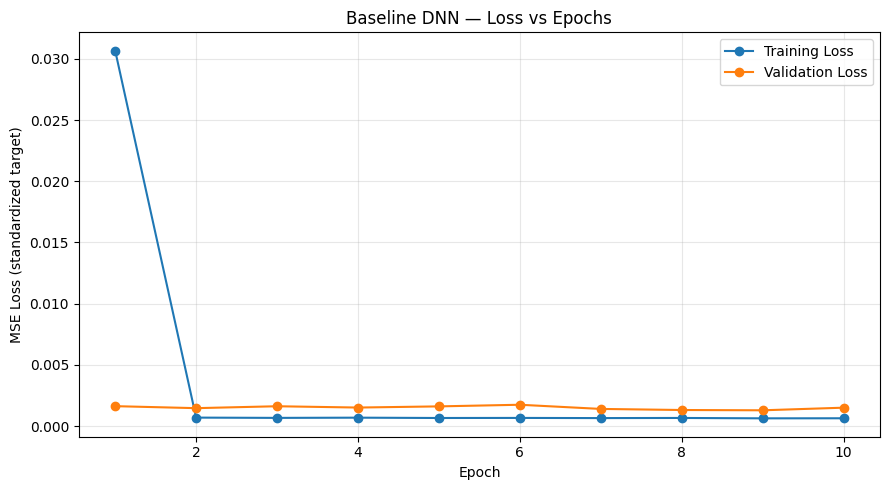

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss (standardized target)")
plt.title("Baseline DNN — Loss vs Epochs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()

with torch.no_grad():
    test_predictions_scaled = (
        model(torch.from_numpy(X_test_scaled).to(device))
        .cpu()
        .numpy()
    )

test_predictions = y_scaler.inverse_transform(test_predictions_scaled)
y_test_original = y_scaler.inverse_transform(y_test_scaled)

mae = mean_absolute_error(y_test_original, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test_original, test_predictions))
r2 = r2_score(y_test_original, test_predictions)

print(f"Test MAE:  {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²:   {r2:.4f}")

Test MAE:  1.1037
Test RMSE: 2.3980
Test R²:   0.9995


In [27]:
print("Python is running!")
print("Notebook environment check")

print("X_train_scaled exists:", "X_train_scaled" in globals())
print("X_val_scaled exists:", "X_val_scaled" in globals())
print("y_train_scaled exists:", "y_train_scaled" in globals())
print("y_val_scaled exists:", "y_val_scaled" in globals())

Python is running!
Notebook environment check
X_train_scaled exists: True
X_val_scaled exists: True
y_train_scaled exists: True
y_val_scaled exists: True


In [28]:
import numpy as np

print("Starting tuning sample preparation...")

print("Training data:", X_train_scaled.shape)
print("Validation data:", X_val_scaled.shape)

rng = np.random.default_rng(42)

n_train_sample = min(20000, len(X_train_scaled))
n_val_sample = min(5000, len(X_val_scaled))

train_indices = rng.choice(
    len(X_train_scaled),
    size=n_train_sample,
    replace=False
)

val_indices = rng.choice(
    len(X_val_scaled),
    size=n_val_sample,
    replace=False
)

X_search = np.concatenate([
    X_train_scaled[train_indices],
    X_val_scaled[val_indices]
])

y_search = np.concatenate([
    y_train_scaled[train_indices].ravel(),
    y_val_scaled[val_indices].ravel()
])

test_fold = np.concatenate([
    np.full(n_train_sample, -1),
    np.zeros(n_val_sample, dtype=int)
])

from sklearn.model_selection import PredefinedSplit

predefined_cv = PredefinedSplit(test_fold)

print("Sample preparation successful!")
print("X_search:", X_search.shape)
print("y_search:", y_search.shape)
print("Fold sizes:", np.unique(test_fold, return_counts=True))

Starting tuning sample preparation...
Training data: (586952, 5)
Validation data: (130212, 5)
Sample preparation successful!
X_search: (25000, 5)
y_search: (25000,)
Fold sizes: (array([-1,  0]), array([20000,  5000]))


In [29]:
import torch
import torch.nn as nn
import numpy as np

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GridSearchCV, PredefinedSplit


class TorchRegressor(RegressorMixin, BaseEstimator):

    def __init__(
        self,
        hidden_layer_sizes=(64, 32),
        learning_rate=0.001,
        optimizer_name="Adam",
        epochs=5,
        batch_size=1024,
        random_state=42
    ):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.learning_rate = learning_rate
        self.optimizer_name = optimizer_name
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state

    def _build_model(self, input_size):
        layers = []
        previous_size = input_size

        for hidden_size in self.hidden_layer_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(nn.ReLU())
            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, 1))

        return nn.Sequential(*layers).to(self.device_)

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        self.device_ = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)

        self.model_ = self._build_model(X.shape[1])

        if self.optimizer_name == "Adam":
            optimizer = torch.optim.Adam(
                self.model_.parameters(),
                lr=self.learning_rate
            )
        elif self.optimizer_name == "SGD":
            optimizer = torch.optim.SGD(
                self.model_.parameters(),
                lr=self.learning_rate
            )
        else:
            raise ValueError("Unsupported optimizer")

        criterion = nn.MSELoss()

        dataset = torch.utils.data.TensorDataset(
            torch.from_numpy(X),
            torch.from_numpy(y)
        )

        loader = torch.utils.data.DataLoader(
            dataset,
            batch_size=self.batch_size,
            shuffle=True
        )

        self.loss_curve_ = []

        for epoch in range(self.epochs):
            self.model_.train()
            total_loss = 0.0
            count = 0

            for batch_X, batch_y in loader:
                batch_X = batch_X.to(self.device_)
                batch_y = batch_y.to(self.device_)

                optimizer.zero_grad()
                predictions = self.model_(batch_X)
                loss = criterion(predictions, batch_y)
                loss.backward()
                optimizer.step()

                total_loss += loss.item() * len(batch_X)
                count += len(batch_X)

            self.loss_curve_.append(total_loss / count)

        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)

        self.model_.eval()

        with torch.no_grad():
            predictions = self.model_(
                torch.from_numpy(X).to(self.device_)
            )

        return predictions.cpu().numpy().ravel()

In [30]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "hidden_layer_sizes": [
        (32,),
        (64, 32)
    ],
    "learning_rate": [
        0.001,
        0.01
    ],
    "optimizer_name": [
        "Adam",
        "SGD"
    ],
    "epochs": [
        5,
        10
    ]
}

grid_search = GridSearchCV(
    estimator=TorchRegressor(batch_size=1024),
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=predefined_cv,
    refit=True,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

grid_search.fit(X_search, y_search)

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest validation MSE:")
print(-grid_search.best_score_)

Fitting 1 folds for each of 16 candidates, totalling 16 fits
[CV] END epochs=5, hidden_layer_sizes=(32,), learning_rate=0.001, optimizer_name=Adam; total time=   0.6s
[CV] END epochs=5, hidden_layer_sizes=(32,), learning_rate=0.001, optimizer_name=SGD; total time=   0.8s
[CV] END epochs=5, hidden_layer_sizes=(32,), learning_rate=0.01, optimizer_name=Adam; total time=   0.6s
[CV] END epochs=5, hidden_layer_sizes=(32,), learning_rate=0.01, optimizer_name=SGD; total time=   0.6s
[CV] END epochs=5, hidden_layer_sizes=(64, 32), learning_rate=0.001, optimizer_name=Adam; total time=   0.9s
[CV] END epochs=5, hidden_layer_sizes=(64, 32), learning_rate=0.001, optimizer_name=SGD; total time=   0.6s
[CV] END epochs=5, hidden_layer_sizes=(64, 32), learning_rate=0.01, optimizer_name=Adam; total time=   0.8s
[CV] END epochs=5, hidden_layer_sizes=(64, 32), learning_rate=0.01, optimizer_name=SGD; total time=   0.6s
[CV] END epochs=10, hidden_layer_sizes=(32,), learning_rate=0.001, optimizer_name=Adam;

In [31]:
import copy
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the best parameters from GridSearchCV
best_params = grid_search.best_params_

print("Selected parameters:", best_params)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Build the selected architecture dynamically
def build_dnn(input_size, hidden_layer_sizes):
    layers = []
    previous_size = input_size

    for hidden_size in hidden_layer_sizes:
        layers.append(nn.Linear(previous_size, hidden_size))
        layers.append(nn.ReLU())
        previous_size = hidden_size

    layers.append(nn.Linear(previous_size, 1))
    return nn.Sequential(*layers)

model_best = build_dnn(
    input_size=X_train_scaled.shape[1],
    hidden_layer_sizes=best_params["hidden_layer_sizes"]
).to(device)

# Create the training DataLoader
train_dataset = TensorDataset(
    torch.from_numpy(X_train_scaled),
    torch.from_numpy(y_train_scaled)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)

X_val_tensor = torch.from_numpy(X_val_scaled).to(device)
y_val_tensor = torch.from_numpy(y_val_scaled).to(device)

criterion = nn.MSELoss()

if best_params["optimizer_name"] == "Adam":
    optimizer = torch.optim.Adam(
        model_best.parameters(),
        lr=best_params["learning_rate"]
    )
else:
    optimizer = torch.optim.SGD(
        model_best.parameters(),
        lr=best_params["learning_rate"]
    )

epochs = best_params["epochs"]

train_losses = []
val_losses = []

for epoch in range(epochs):
    model_best.train()
    total_loss = 0.0
    total_samples = 0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        predictions = model_best(batch_X)
        loss = criterion(predictions, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_X)
        total_samples += len(batch_X)

    train_loss = total_loss / total_samples
    train_losses.append(train_loss)

    model_best.eval()
    with torch.no_grad():
        val_predictions = model_best(X_val_tensor)
        val_loss = criterion(val_predictions, y_val_tensor).item()

    val_losses.append(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Train MSE: {train_loss:.6f} | "
        f"Validation MSE: {val_loss:.6f}"
    )

Selected parameters: {'epochs': 10, 'hidden_layer_sizes': (32,), 'learning_rate': 0.01, 'optimizer_name': 'Adam'}
Epoch 01/10 | Train MSE: 0.003270 | Validation MSE: 0.001375
Epoch 02/10 | Train MSE: 0.000699 | Validation MSE: 0.002716
Epoch 03/10 | Train MSE: 0.000730 | Validation MSE: 0.003246
Epoch 04/10 | Train MSE: 0.000771 | Validation MSE: 0.001419
Epoch 05/10 | Train MSE: 0.000799 | Validation MSE: 0.001318
Epoch 06/10 | Train MSE: 0.000754 | Validation MSE: 0.001678
Epoch 07/10 | Train MSE: 0.000719 | Validation MSE: 0.001488
Epoch 08/10 | Train MSE: 0.000733 | Validation MSE: 0.001976
Epoch 09/10 | Train MSE: 0.000744 | Validation MSE: 0.001799
Epoch 10/10 | Train MSE: 0.000673 | Validation MSE: 0.002617


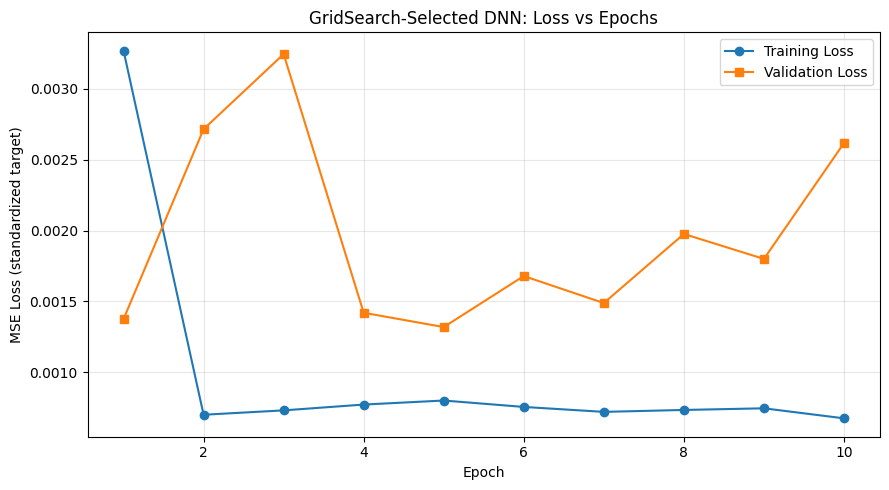

In [32]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss (standardized target)")
plt.title("GridSearch-Selected DNN: Loss vs Epochs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

class RegularizedDNN(nn.Module):
    def __init__(self, input_size=5, hidden_sizes=(32,), dropout_rate=0.0):
        super().__init__()

        layers = []
        previous_size = input_size

        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(nn.ReLU())

            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))

            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


Device: cuda


In [34]:

def run_experiment(
    name,
    dropout_rate=0.0,
    weight_decay=0.0,
    max_epochs=10,
    early_stopping=False,
    patience=3
):
    torch.manual_seed(42)
    np.random.seed(42)

    model = RegularizedDNN(
        input_size=X_train_scaled.shape[1],
        hidden_sizes=(32,),
        dropout_rate=dropout_rate
    ).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.01,
        weight_decay=weight_decay
    )

    criterion = nn.MSELoss()

    train_dataset = TensorDataset(
        torch.from_numpy(X_train_scaled),
        torch.from_numpy(y_train_scaled)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=1024,
        shuffle=True
    )

    X_val_tensor = torch.from_numpy(X_val_scaled).to(device)
    y_val_tensor = torch.from_numpy(y_val_scaled).to(device)

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(max_epochs):
        model.train()
        total_loss = 0.0
        total_samples = 0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            predictions = model(batch_X)
            loss = criterion(predictions, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_X)
            total_samples += len(batch_X)

        train_loss = total_loss / total_samples
        train_losses.append(train_loss)

        model.eval()
        with torch.no_grad():
            val_predictions = model(X_val_tensor)
            val_loss = criterion(
                val_predictions, y_val_tensor
            ).item()

        val_losses.append(val_loss)

        print(
            f"{name} | Epoch {epoch + 1:02d} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if early_stopping and epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

    # Restore the best validation checkpoint for every configuration.
    model.load_state_dict(best_state)

    return {
        "name": name,
        "model": model,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss
    }


experiments = {}

experiments["Baseline"] = run_experiment(
    name="Baseline",
    max_epochs=10
)

experiments["Dropout"] = run_experiment(
    name="Dropout",
    dropout_rate=0.2,
    max_epochs=10
)

experiments["L2"] = run_experiment(
    name="L2",
    weight_decay=0.001,
    max_epochs=10
)

experiments["Dropout + L2 + Early Stopping"] = run_experiment(
    name="Dropout + L2 + Early Stopping",
    dropout_rate=0.2,
    weight_decay=0.001,
    max_epochs=20,
    early_stopping=True,
    patience=3
)


Baseline | Epoch 01 | Train MSE: 0.003270 | Val MSE: 0.001375
Baseline | Epoch 02 | Train MSE: 0.000699 | Val MSE: 0.002716
Baseline | Epoch 03 | Train MSE: 0.000730 | Val MSE: 0.003246
Baseline | Epoch 04 | Train MSE: 0.000771 | Val MSE: 0.001419
Baseline | Epoch 05 | Train MSE: 0.000799 | Val MSE: 0.001318
Baseline | Epoch 06 | Train MSE: 0.000754 | Val MSE: 0.001678
Baseline | Epoch 07 | Train MSE: 0.000719 | Val MSE: 0.001488
Baseline | Epoch 08 | Train MSE: 0.000733 | Val MSE: 0.001976
Baseline | Epoch 09 | Train MSE: 0.000744 | Val MSE: 0.001799
Baseline | Epoch 10 | Train MSE: 0.000673 | Val MSE: 0.002617
Dropout | Epoch 01 | Train MSE: 0.026609 | Val MSE: 0.003869
Dropout | Epoch 02 | Train MSE: 0.022850 | Val MSE: 0.001678
Dropout | Epoch 03 | Train MSE: 0.023339 | Val MSE: 0.015585
Dropout | Epoch 04 | Train MSE: 0.024984 | Val MSE: 0.021602
Dropout | Epoch 05 | Train MSE: 0.023842 | Val MSE: 0.027803
Dropout | Epoch 06 | Train MSE: 0.023770 | Val MSE: 0.006812
Dropout | Epoc

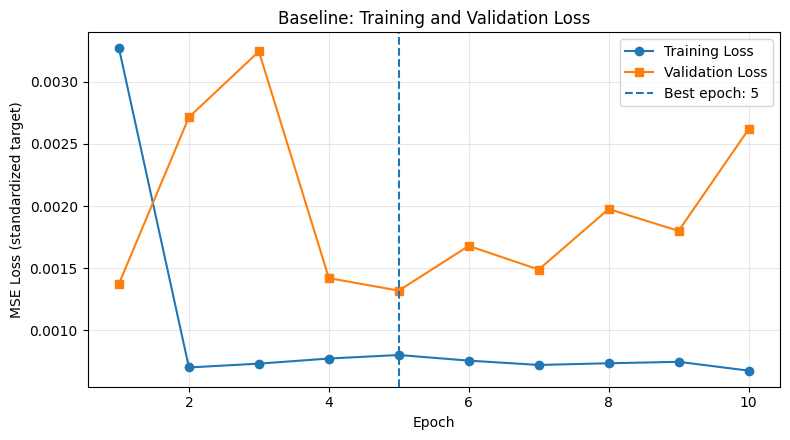

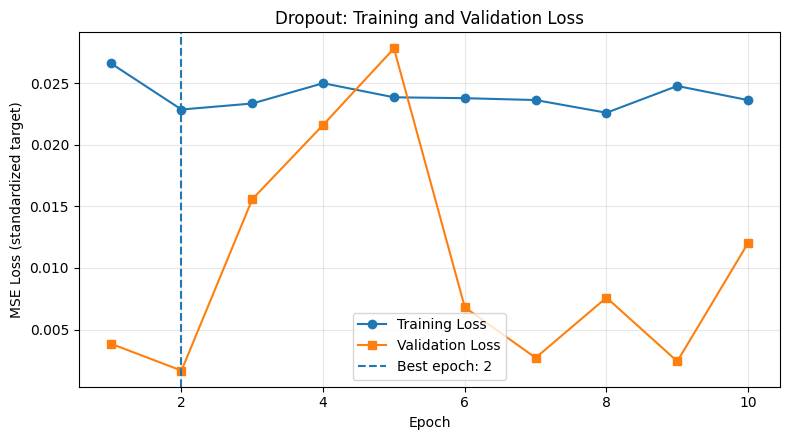

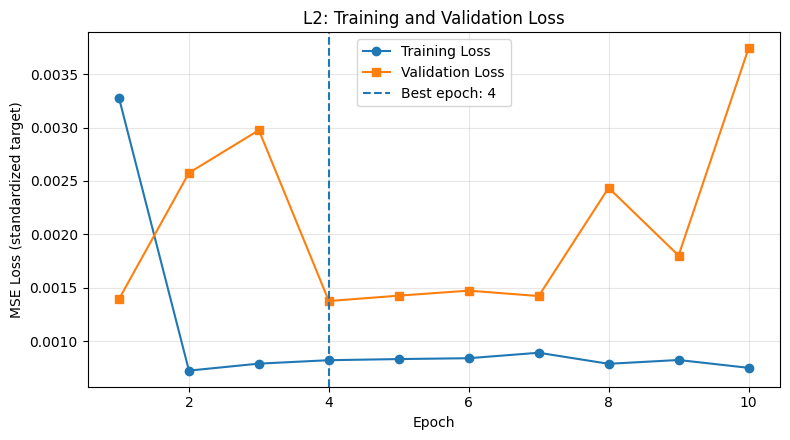

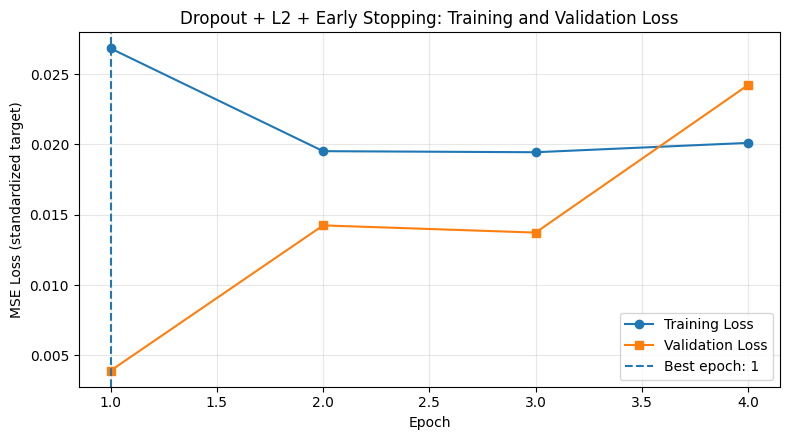

In [35]:

for name, result in experiments.items():
    epochs_range = range(1, len(result["train_losses"]) + 1)

    plt.figure(figsize=(8, 4.5))
    plt.plot(
        epochs_range, result["train_losses"],
        marker="o", label="Training Loss"
    )
    plt.plot(
        epochs_range, result["val_losses"],
        marker="s", label="Validation Loss"
    )

    plt.axvline(
        result["best_epoch"],
        linestyle="--",
        label=f"Best epoch: {result['best_epoch']}"
    )

    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss (standardized target)")
    plt.title(f"{name}: Training and Validation Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


In [36]:

results = []

X_test_tensor = torch.from_numpy(X_test_scaled).to(device)
actual_prices = y_scaler.inverse_transform(y_test_scaled).ravel()

for name, result in experiments.items():
    model = result["model"]
    model.eval()

    with torch.no_grad():
        predictions_scaled = model(X_test_tensor).cpu().numpy()

    predictions = y_scaler.inverse_transform(
        predictions_scaled
    ).ravel()

    mae = mean_absolute_error(actual_prices, predictions)
    rmse = np.sqrt(mean_squared_error(actual_prices, predictions))
    r2 = r2_score(actual_prices, predictions)

    # Avoid division by zero when calculating relative error.
    nonzero = np.abs(actual_prices) > 1e-8
    accuracy_5 = (
        np.mean(
            np.abs(predictions[nonzero] - actual_prices[nonzero])
            <= 0.05 * np.abs(actual_prices[nonzero])
        ) * 100
    )

    results.append({
        "Model": name,
        "Best Epoch": result["best_epoch"],
        "Best Validation MSE": result["best_val_loss"],
        "Test MAE": mae,
        "Test RMSE": rmse,
        "Test R²": r2,
        "Within 5% (%)": accuracy_5
    })

results_df = pd.DataFrame(results).sort_values("Test RMSE")
display(results_df.round(4))


,Model,Best Epoch,Best Validation MSE,Test MAE,Test RMSE,Test R²,Within 5% (%)
0,Baseline,5,0.0013,0.9999,2.2208,0.9995,96.8449
2,L2,4,0.0014,1.0437,2.2632,0.9995,96.0086
1,Dropout,2,0.0017,1.2645,2.4974,0.9994,90.7375
3,Dropout + L2 + Early Stopping,1,0.0039,2.0928,3.9745,0.9985,86.0380
